# Ames Housing Dataset — Exploratory Data Analysis (EDA)

**Objective:** Explore the Ames Housing data and understand which house characteristics are associated with sale prices. This notebook performs EDA only; it does not train a machine-learning model.

**Dataset:** Kaggle House Prices: Advanced Regression Techniques (`train.csv`)

> Place `train.csv` in the same folder as this notebook before running.

In [6]:
import pandas as pd

df = pd.read_csv('/content/train.csv')

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/train.csv')

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
from google.colab import files
uploaded = files.upload()

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [10]:
from google.colab import files
uploaded = files.upload()

MessageError: RangeError: Maximum call stack size exceeded.

In [11]:
display(df.info())
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

None

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [12]:
column_summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(),
    "missing_values": df.isna().sum()
}).sort_values("missing_values", ascending=False)

display(column_summary)

,dtype,unique_values,missing_values
PoolQC,object,3,1453
MiscFeature,object,4,1406
Alley,object,2,1369
Fence,object,4,1179
MasVnrType,object,3,872
...,...,...,...
MoSold,int64,12,0
YrSold,int64,5,0
SaleType,object,9,0
SaleCondition,object,6,0


,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


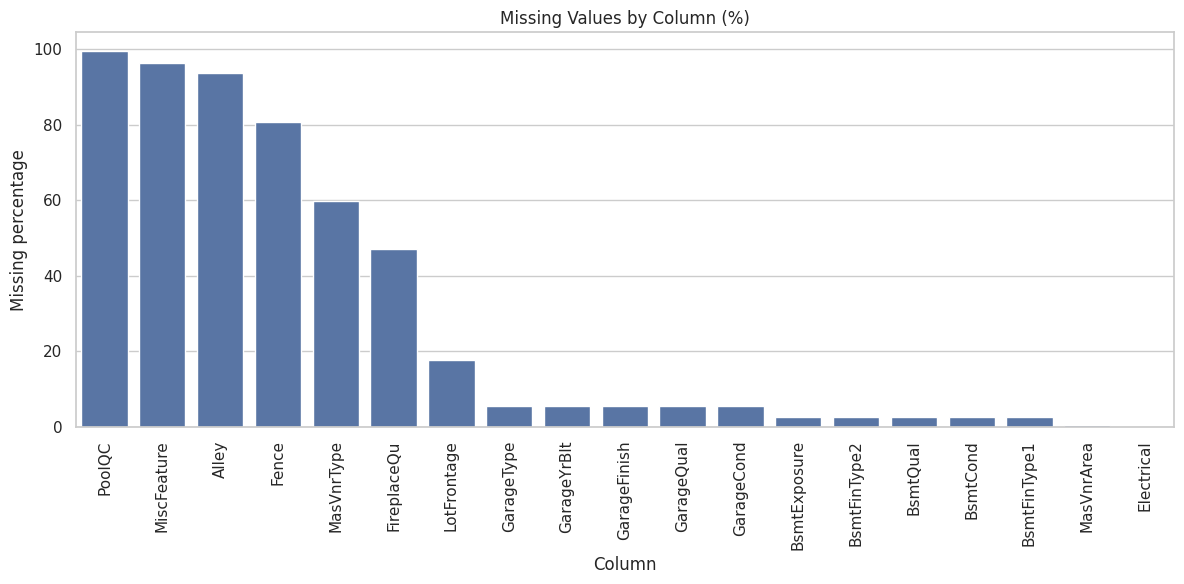

In [13]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": (missing / len(df) * 100).round(2)
})

display(missing_table)

if not missing_table.empty:
    plt.figure(figsize=(12, 6))
    sns.barplot(x=missing_table.index, y=missing_table["missing_percent"])
    plt.title("Missing Values by Column (%)")
    plt.xlabel("Column")
    plt.ylabel("Missing percentage")
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [14]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 38
Categorical columns: 43


In [15]:
target = "SalePrice"

print("Mean:", df[target].mean())
print("Median:", df[target].median())
print("Mode:", df[target].mode().iloc[0])
print("Standard deviation:", df[target].std())
print("Minimum:", df[target].min())
print("Maximum:", df[target].max())
print("Skewness:", df[target].skew())

Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard deviation: 79442.50288288663
Minimum: 34900
Maximum: 755000
Skewness: 1.8828757597682129


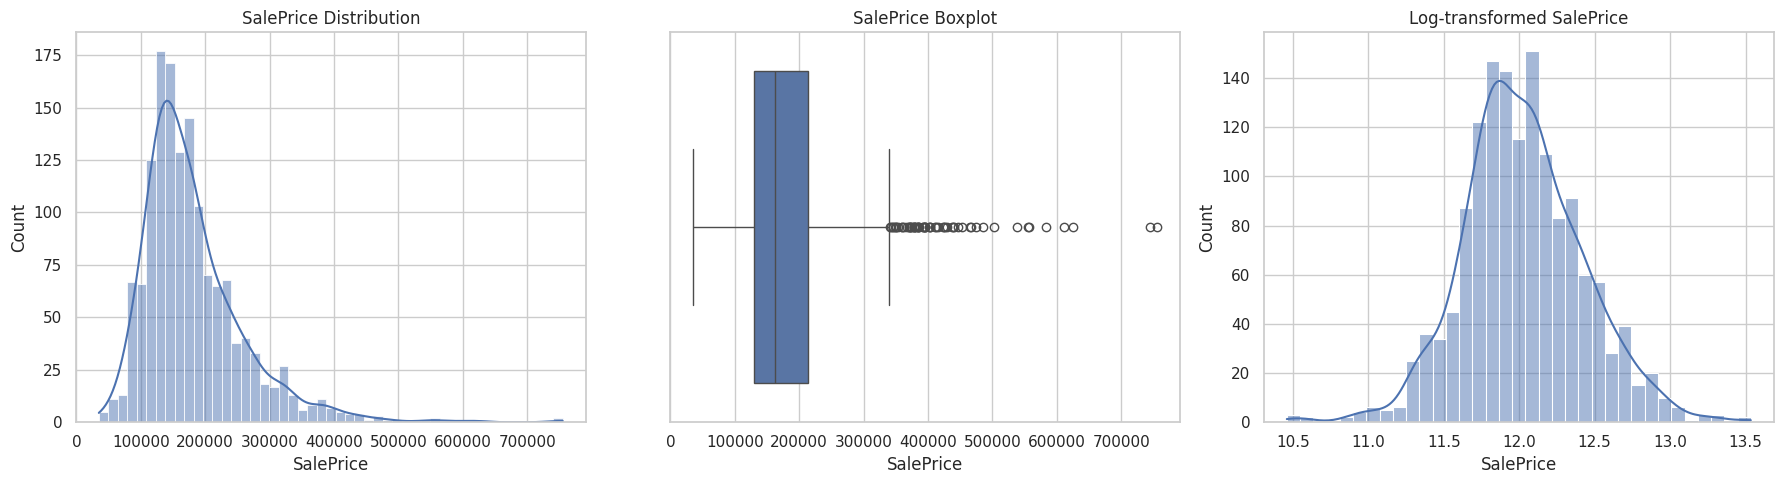

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution")

sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Boxplot")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log-transformed SalePrice")

plt.tight_layout()
plt.show()

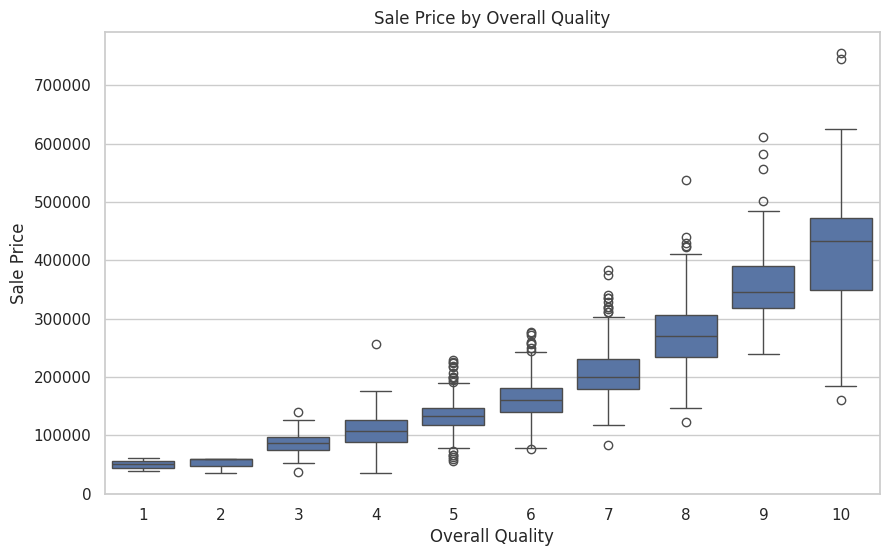

In [17]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("Sale Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

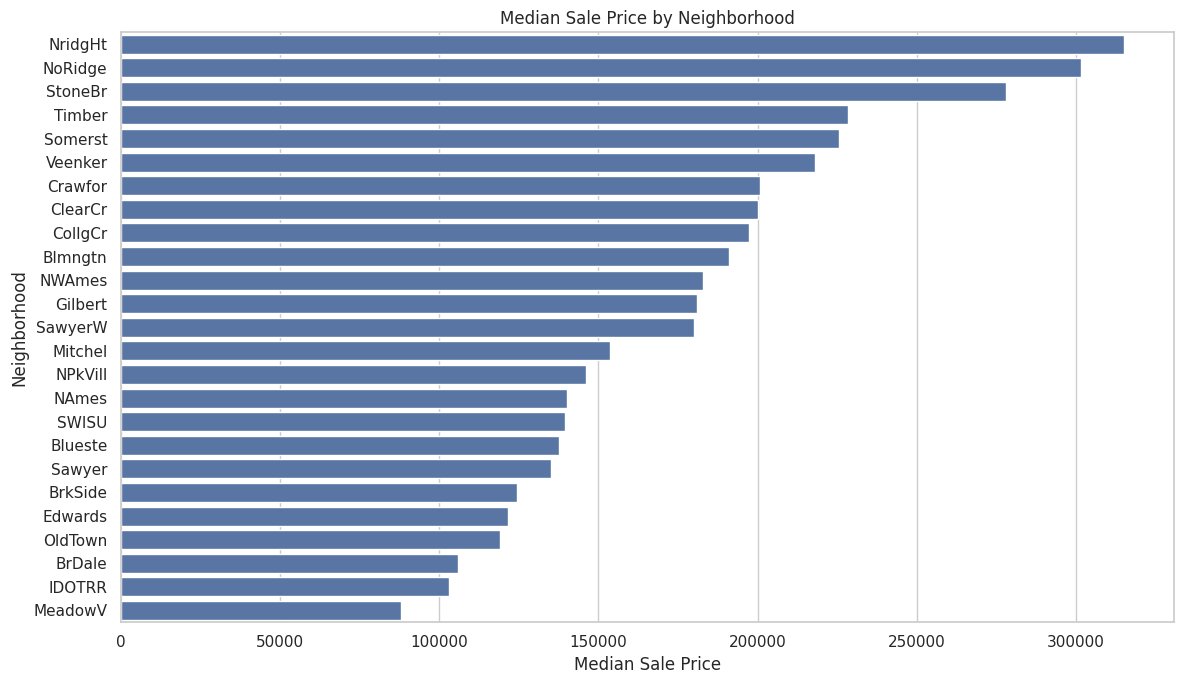

,median_sale_price
Neighborhood,
NridgHt,315000.0
NoRidge,301500.0
StoneBr,278000.0
Timber,228475.0
Somerst,225500.0
Veenker,218000.0
Crawfor,200624.0
ClearCr,200250.0
CollgCr,197200.0


In [18]:
neighborhood_prices = (
    df.groupby("Neighborhood")["SalePrice"]
      .median()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))
sns.barplot(x=neighborhood_prices.values, y=neighborhood_prices.index)
plt.title("Median Sale Price by Neighborhood")
plt.xlabel("Median Sale Price")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

display(neighborhood_prices.to_frame("median_sale_price"))

,correlation_with_SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


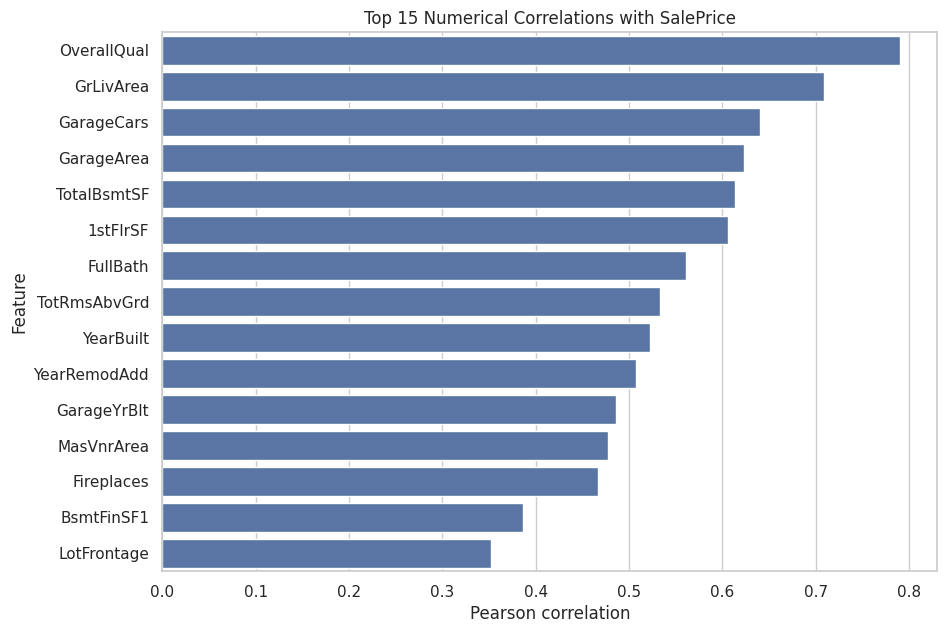

In [19]:
corr_with_price = df[numeric_cols].corr(numeric_only=True)["SalePrice"].drop("SalePrice")
corr_with_price = corr_with_price.sort_values(key=lambda s: s.abs(), ascending=False)

display(corr_with_price.head(15).to_frame("correlation_with_SalePrice"))

plt.figure(figsize=(10, 7))
sns.barplot(x=corr_with_price.head(15).values,
            y=corr_with_price.head(15).index)
plt.title("Top 15 Numerical Correlations with SalePrice")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.show()

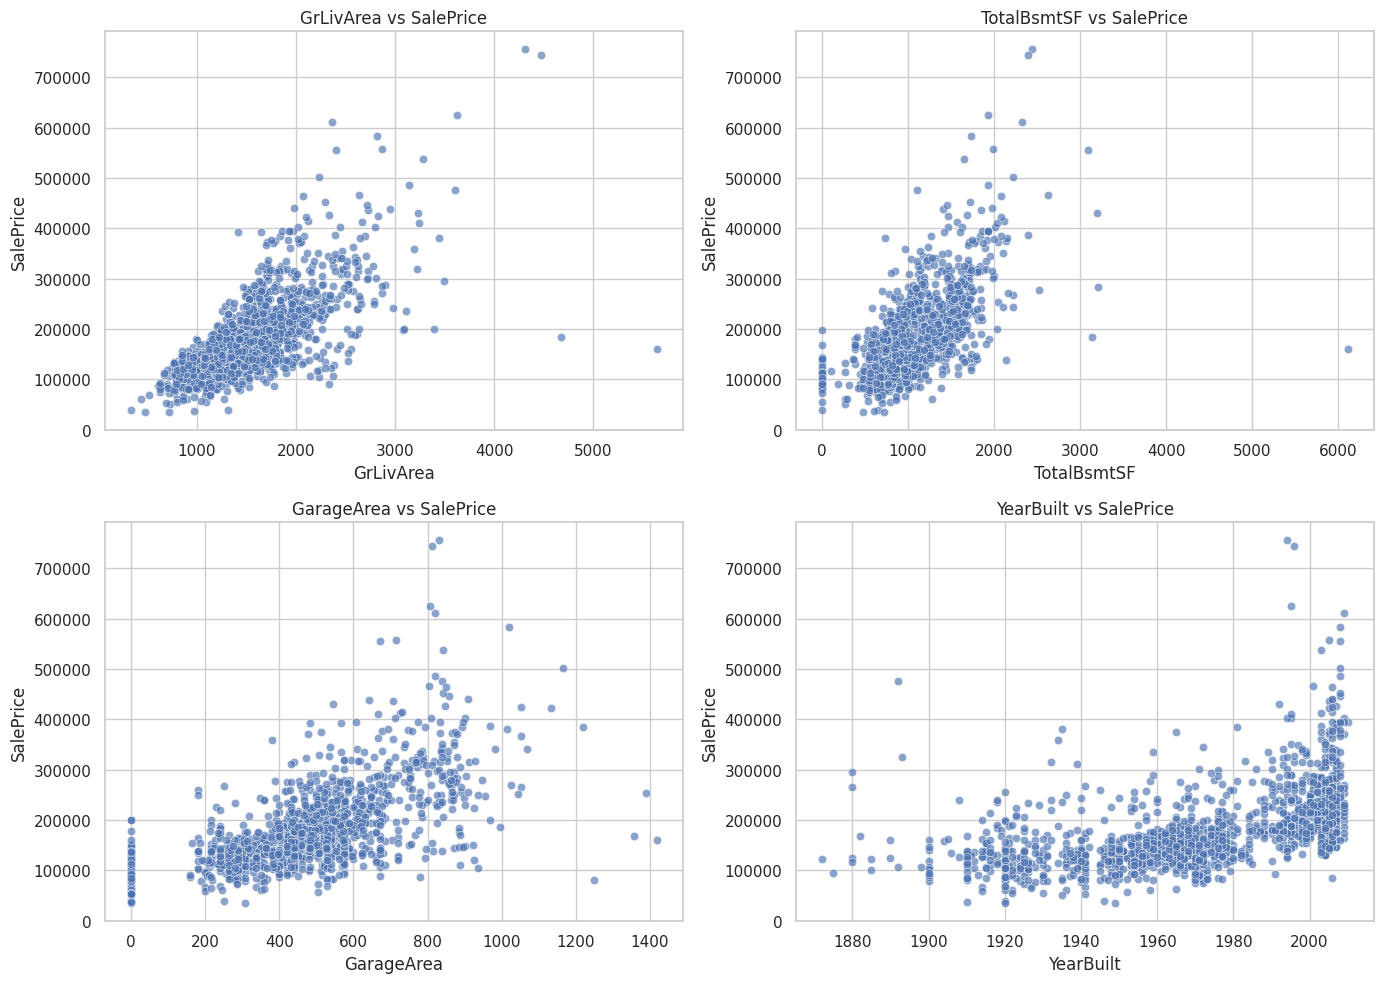

In [20]:
features = ["GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for feature, ax in zip(features, axes.flat):
    sns.scatterplot(data=df, x=feature, y="SalePrice", ax=ax, alpha=0.65)
    ax.set_title(f"{feature} vs SalePrice")

plt.tight_layout()
plt.show()

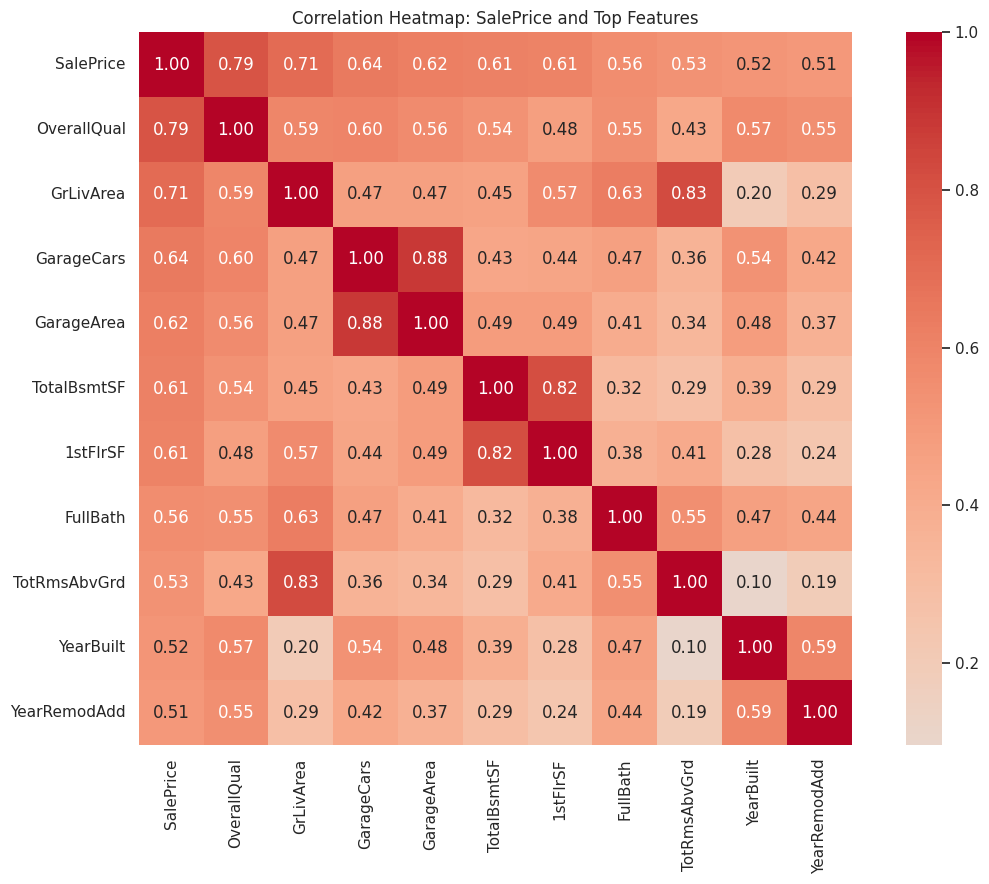

In [21]:
top_features = corr_with_price.head(10).index.tolist()
heatmap_cols = ["SalePrice"] + top_features

plt.figure(figsize=(12, 9))
sns.heatmap(df[heatmap_cols].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap: SalePrice and Top Features")
plt.tight_layout()
plt.show()

In [23]:
def iqr_outlier_rows(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return data[(data[column] < lower) | (data[column] > upper)]

for column in ["SalePrice", "GrLivArea"]:
    outliers = iqr_outlier_rows(df, column)
    print(f"{column}: {len(outliers)} IQR outliers")
    display(outliers[["Id", column, "SalePrice"]].head(10))

SalePrice: 61 IQR outliers


,Id,SalePrice,SalePrice
11,12,345000,345000
53,54,385000,385000
58,59,438780,438780
112,113,383970,383970
151,152,372402,372402
161,162,412500,412500
178,179,501837,501837
185,186,475000,475000
224,225,386250,386250
231,232,403000,403000


GrLivArea: 31 IQR outliers


,Id,GrLivArea,SalePrice
58,59,2945,438780
118,119,3222,320000
185,186,3608,475000
197,198,3112,235000
231,232,2794,403000
304,305,3493,295000
324,325,2978,242000
496,497,3228,430000
523,524,4676,184750
583,584,2775,325000


In [24]:
print("Duplicate rows:", df.duplicated().sum())

# Check for impossible or suspicious values
if "YearBuilt" in df.columns and "YrSold" in df.columns:
    print("YearBuilt later than YrSold:", (df["YearBuilt"] > df["YrSold"]).sum())

for col in ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"]:
    if col in df.columns:
        print(f"Negative values in {col}:", (df[col] < 0).sum())

Duplicate rows: 0
YearBuilt later than YrSold: 0
Negative values in LotArea: 0
Negative values in GrLivArea: 0
Negative values in TotalBsmtSF: 0
Negative values in GarageArea: 0


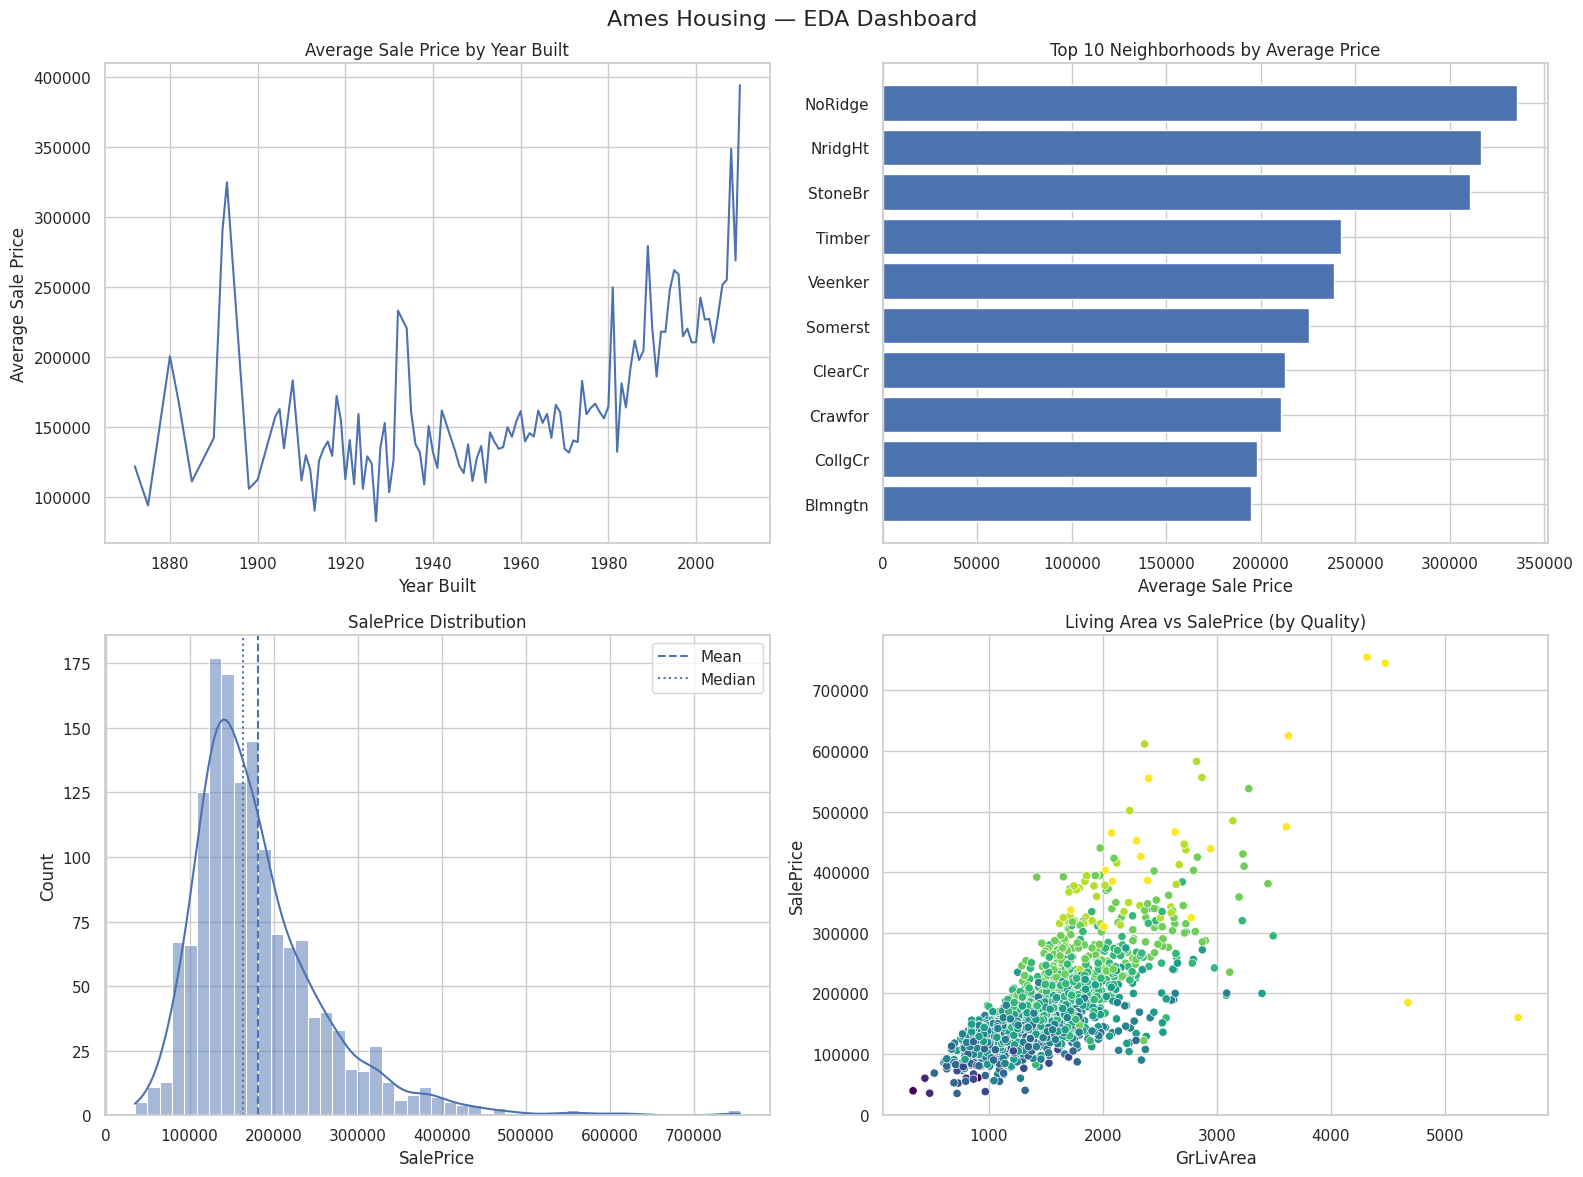

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Average sale price by year built
year_price = df.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(year_price.index, year_price.values)
axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")

# Top 10 neighborhoods by mean sale price
top_neighborhoods = df.groupby("Neighborhood")["SalePrice"].mean().nlargest(10).sort_values()
axes[0, 1].barh(top_neighborhoods.index, top_neighborhoods.values)
axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")

# SalePrice distribution with mean and median
sns.histplot(df["SalePrice"], kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df["SalePrice"].mean(), linestyle="--", label="Mean")
axes[1, 0].axvline(df["SalePrice"].median(), linestyle=":", label="Median")
axes[1, 0].set_title("SalePrice Distribution")
axes[1, 0].legend()

# Living area vs sale price, coloured by quality
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice",
                hue="OverallQual", palette="viridis", ax=axes[1, 1], legend=False)
axes[1, 1].set_title("Living Area vs SalePrice (by Quality)")

plt.suptitle("Ames Housing — EDA Dashboard", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()